In [9]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn statsmodels

In [10]:
from google.colab import files
import zipfile
import os
import io

# Upload the original ZIP file
uploaded = files.upload()

# Find the uploaded ZIP file
zip_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("Please upload the wine quality ZIP file.")

zip_name = zip_files[0]

# Extract the ZIP file
DATA_DIR = "/content/wine_quality_data"
os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as z:
    z.extractall(DATA_DIR)

print("ZIP file extracted successfully.")
print("Files found:")

for root, dirs, filenames in os.walk(DATA_DIR):
    for filename in filenames:
        print(os.path.join(root, filename))

Saving wine+quality.zip to wine+quality (2).zip
ZIP file extracted successfully.
Files found:
/content/wine_quality_data/winequality-white.csv
/content/wine_quality_data/winequality-red.csv
/content/wine_quality_data/winequality.names


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.preprocessing import StandardScaler

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Select the red wine dataset
DATASET_FILE = "winequality-red.csv"

# Find the CSV file inside the extracted folder
csv_path = None

for root, dirs, filenames in os.walk(DATA_DIR):
    if DATASET_FILE in filenames:
        csv_path = os.path.join(root, DATASET_FILE)
        break

if csv_path is None:
    raise FileNotFoundError("Could not find " + DATASET_FILE)

# Read the dataset
df = pd.read_csv(csv_path, sep=";")

# Create a folder for graphs and results
OUTPUT_DIR = "/content/wine_quality_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset loaded successfully!
Dataset shape: (1599, 12)
Number of rows: 1599
Number of columns: 12

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

First five rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [12]:
# Attributes required for Task 1
attributes = [
    "alcohol",
    "volatile acidity",
    "residual sugar"
]

stats_rows = []

for column in attributes:
    s = df[column]

    # Calculate all modes
    mode_values = s.mode().tolist()

    stats_rows.append({
        "Attribute": column,
        "Mean": s.mean(),
        "Median": s.median(),
        "Mode": ", ".join(str(x) for x in mode_values),
        "Standard Deviation": s.std(ddof=1),
        "Skewness": s.skew(),
        "Coefficient of Variation (%)":
            (s.std(ddof=1) / s.mean()) * 100
    })

stats_df = pd.DataFrame(stats_rows)

print("TASK 1(a): DESCRIPTIVE STATISTICS")
display(stats_df.round(4))

# Save the table for the report
stats_df.to_csv(
    os.path.join(OUTPUT_DIR, "task1_descriptive_statistics.csv"),
    index=False
)

TASK 1(a): DESCRIPTIVE STATISTICS


,Attribute,Mean,Median,Mode,Standard Deviation,Skewness,Coefficient of Variation (%)
0,alcohol,10.4230,10.20,9.5,1.0657,0.8608,10.2242
1,volatile acidity,0.5278,0.52,0.6,0.1791,0.6716,33.9244
2,residual sugar,2.5388,2.20,2.0,1.4099,4.5407,55.5351


In [13]:
cv_column = "Coefficient of Variation (%)"

highest_cv_row = stats_df.loc[
    stats_df[cv_column].idxmax()
]

print("TASK 1(b): RELATIVE VARIABILITY")
print()

for _, row in stats_df.iterrows():
    print(
        f"{row['Attribute']}: "
        f"CV = {row[cv_column]:.2f}%"
    )

print("\nAttribute with the greatest relative variability:")
print(highest_cv_row["Attribute"])

print(
    f"Coefficient of Variation = "
    f"{highest_cv_row[cv_column]:.2f}%"
)

TASK 1(b): RELATIVE VARIABILITY

alcohol: CV = 10.22%
volatile acidity: CV = 33.92%
residual sugar: CV = 55.54%

Attribute with the greatest relative variability:
residual sugar
Coefficient of Variation = 55.54%


In [14]:
alcohol_quality_corr = df["alcohol"].corr(df["quality"])

print("TASK 1(c): PEARSON CORRELATION")
print(
    f"Pearson correlation between alcohol and quality: "
    f"{alcohol_quality_corr:.4f}"
)

if alcohol_quality_corr > 0:
    direction = "positive"
else:
    direction = "negative"

strength_value = abs(alcohol_quality_corr)

if strength_value < 0.3:
    strength = "weak"
elif strength_value < 0.7:
    strength = "moderate"
else:
    strength = "strong"

print(f"Direction: {direction}")
print(f"Strength: {strength}")

print(
    "\nInterpretation: Alcohol content has a moderate positive "
    "correlation with wine quality. In this dataset, higher "
    "alcohol content tends to be associated with higher quality scores."
)

TASK 1(c): PEARSON CORRELATION
Pearson correlation between alcohol and quality: 0.4762
Direction: positive
Strength: moderate

Interpretation: Alcohol content has a moderate positive correlation with wine quality. In this dataset, higher alcohol content tends to be associated with higher quality scores.


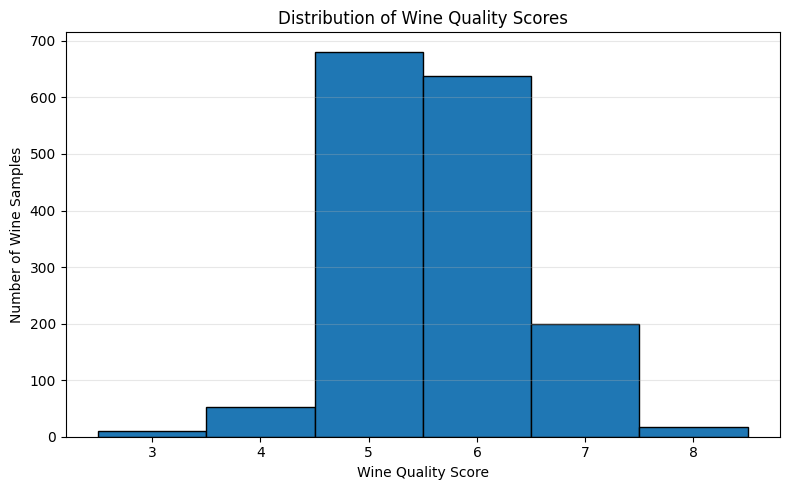

Quality score frequencies:


,Quality Score,Number of Wines
0,3,10
1,4,53
2,5,681
3,6,638
4,7,199
5,8,18


In [15]:
plt.figure(figsize=(8, 5))

quality_bins = np.arange(
    df["quality"].min() - 0.5,
    df["quality"].max() + 1.5,
    1
)

plt.hist(
    df["quality"],
    bins=quality_bins,
    edgecolor="black"
)

plt.xlabel("Wine Quality Score")
plt.ylabel("Number of Wine Samples")
plt.title("Distribution of Wine Quality Scores")
plt.xticks(sorted(df["quality"].unique()))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "01_quality_histogram.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Quality score frequencies:")
display(
    df["quality"]
    .value_counts()
    .sort_index()
    .rename_axis("Quality Score")
    .reset_index(name="Number of Wines")
)

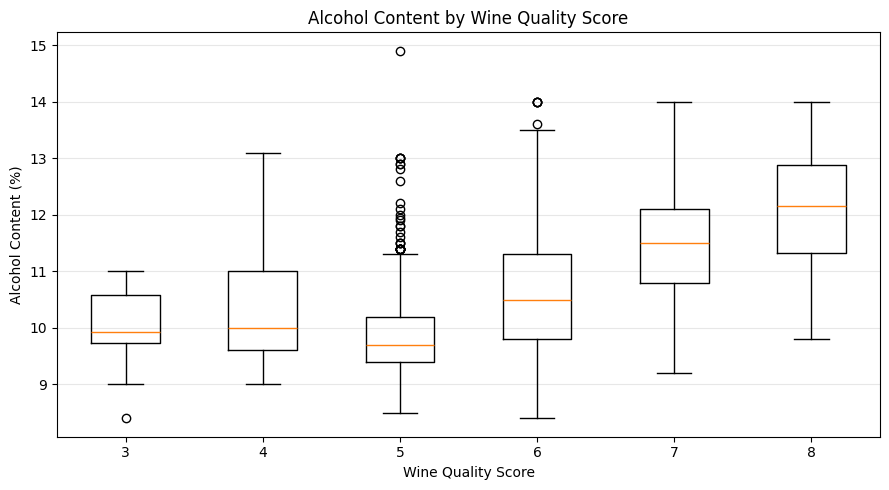

In [16]:
plt.figure(figsize=(9, 5))

quality_order = sorted(df["quality"].unique())

box_data = [
    df.loc[df["quality"] == q, "alcohol"]
    for q in quality_order
]

plt.boxplot(box_data)

plt.xlabel("Wine Quality Score")
plt.ylabel("Alcohol Content (%)")
plt.title("Alcohol Content by Wine Quality Score")
plt.xticks(
    range(1, len(quality_order) + 1),
    quality_order
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "02_alcohol_boxplot.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

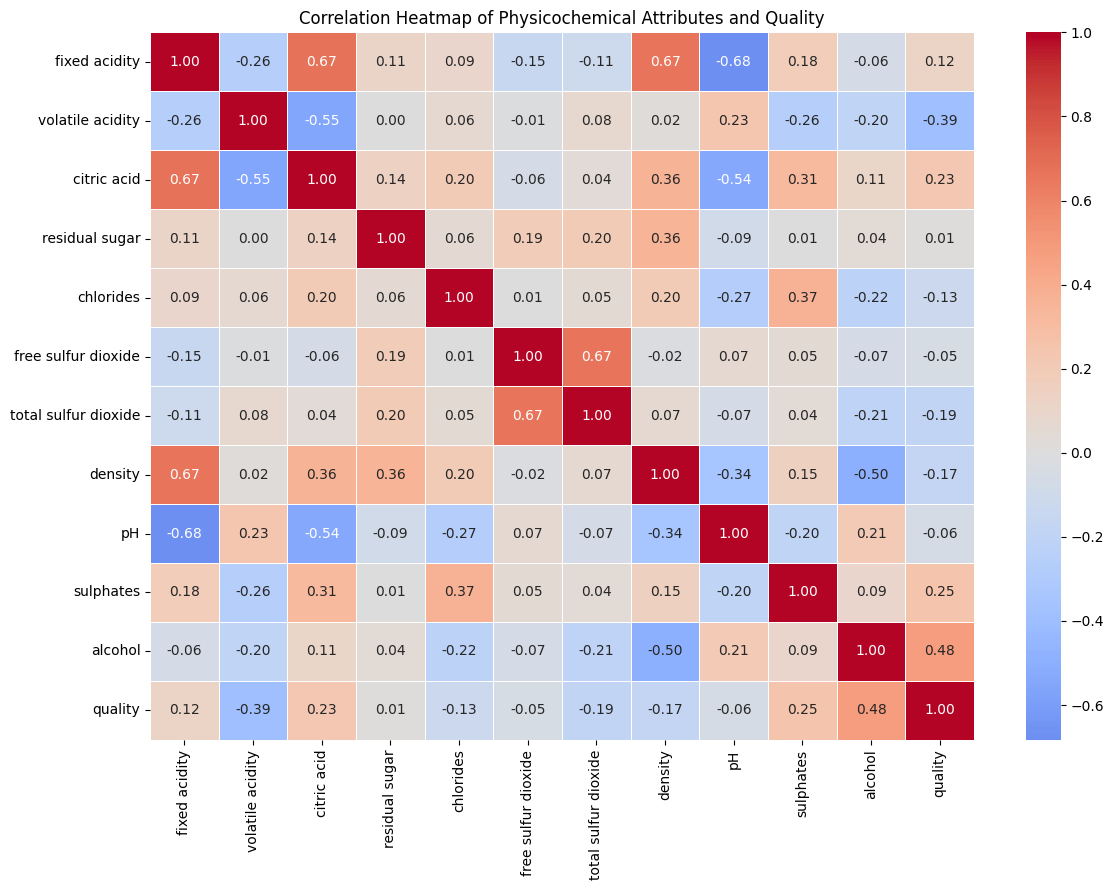

In [17]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Physicochemical Attributes and Quality")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "03_correlation_heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
quality_correlations = (
    correlation_matrix["quality"]
    .drop("quality")
)

# Sort by absolute correlation, from strongest to weakest
top_two_correlations = quality_correlations.loc[
    quality_correlations.abs().sort_values(
        ascending=False
    ).index
].head(2)

top_two_df = top_two_correlations.rename(
    "Pearson Correlation with Quality"
).reset_index()

top_two_df.columns = [
    "Attribute",
    "Pearson Correlation with Quality"
]

print("TASK 2(d): TWO STRONGEST ASSOCIATIONS WITH QUALITY")
display(top_two_df.round(4))

for _, row in top_two_df.iterrows():
    if row["Pearson Correlation with Quality"] > 0:
        direction = "positive"
    else:
        direction = "negative"

    print(
        f"{row['Attribute']}: {direction} association, "
        f"r = {row['Pearson Correlation with Quality']:.4f}"
    )

top_two_df.to_csv(
    os.path.join(OUTPUT_DIR, "task2_top_correlations.csv"),
    index=False
)

TASK 2(d): TWO STRONGEST ASSOCIATIONS WITH QUALITY


,Attribute,Pearson Correlation with Quality
0,alcohol,0.4762
1,volatile acidity,-0.3906


alcohol: positive association, r = 0.4762
volatile acidity: negative association, r = -0.3906


In [20]:
# Independent variables: all 11 physicochemical attributes
X = df.drop(columns=["quality"])

# Dependent variable: wine quality
y = df["quality"]

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of predictor attributes:", X.shape[1])

# Create and train the multiple linear regression model
model = LinearRegression()

model.fit(X_train, y_train)

# Predict quality scores for the test data
y_pred = model.predict(X_test)

print("\nMultiple Linear Regression model trained successfully.")

Training samples: 1279
Testing samples: 320
Number of predictor attributes: 11

Multiple Linear Regression model trained successfully.


In [21]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

metrics_df = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R-squared"],
    "Test Set Value": [mae, mse, rmse, r2]
})

print("TASK 3(c): REGRESSION MODEL EVALUATION")
display(metrics_df.round(4))

metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "task3_model_metrics.csv"),
    index=False
)

TASK 3(c): REGRESSION MODEL EVALUATION


,Metric,Test Set Value
0,MAE,0.5035
1,MSE,0.3900
2,RMSE,0.6245
3,R-squared,0.4032


In [22]:
# Standardize predictors using training data only
x_scaler = StandardScaler()

X_train_scaled = x_scaler.fit_transform(X_train)

# Standardize the target using training data only
y_train_mean = y_train.mean()
y_train_std = y_train.std(ddof=0)

y_train_scaled = (
    y_train - y_train_mean
) / y_train_std

# Fit a regression model on standardized training data
standardized_model = LinearRegression()

standardized_model.fit(
    X_train_scaled,
    y_train_scaled
)

# Extract standardized coefficients
standardized_coefficients_df = pd.DataFrame({
    "Attribute": X.columns,
    "Standardized Coefficient": standardized_model.coef_
})

# Sort by absolute coefficient magnitude
standardized_coefficients_df["Absolute Coefficient"] = (
    standardized_coefficients_df[
        "Standardized Coefficient"
    ].abs()
)

standardized_coefficients_df = (
    standardized_coefficients_df
    .sort_values(
        "Absolute Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

print("TASK 3(d): STANDARDIZED REGRESSION COEFFICIENTS")
display(
    standardized_coefficients_df[
        ["Attribute", "Standardized Coefficient"]
    ].round(4)
)

print("\nTwo most influential predictors:")
display(
    standardized_coefficients_df[
        ["Attribute", "Standardized Coefficient"]
    ].head(2).round(4)
)

standardized_coefficients_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "task3_standardized_coefficients.csv"
    ),
    index=False
)

TASK 3(d): STANDARDIZED REGRESSION COEFFICIENTS


,Attribute,Standardized Coefficient
0,alcohol,0.3678
1,volatile acidity,-0.2225
2,sulphates,0.1820
3,total sulfur dioxide,-0.1488
4,chlorides,-0.1104
5,pH,-0.0751
6,free sulfur dioxide,0.0719
7,fixed acidity,0.0493
8,citric acid,-0.0341
9,density,-0.0238



Two most influential predictors:


,Attribute,Standardized Coefficient
0,alcohol,0.3678
1,volatile acidity,-0.2225


In [23]:
# Calculate VIF using training predictors
X_vif = add_constant(X_train.astype(float))

vif_rows = []

# Index 0 is the intercept, so predictors start at index 1
for i, column in enumerate(X_train.columns, start=1):
    vif_value = variance_inflation_factor(
        X_vif.values,
        i
    )

    vif_rows.append({
        "Attribute": column,
        "VIF": vif_value
    })

vif_df = pd.DataFrame(vif_rows)

vif_df = vif_df.sort_values(
    "VIF",
    ascending=False
).reset_index(drop=True)

print("MULTICOLLINEARITY CHECK: VARIANCE INFLATION FACTOR")
display(vif_df.round(3))

print("\nInterpretation:")
print("VIF values around 1 indicate little multicollinearity.")
print("Values above 5 can indicate a potential issue.")
print("Values above 10 are commonly treated as a stronger warning.")

vif_df.to_csv(
    os.path.join(OUTPUT_DIR, "task3_vif_results.csv"),
    index=False
)

MULTICOLLINEARITY CHECK: VARIANCE INFLATION FACTOR


,Attribute,VIF
0,fixed acidity,7.375
1,density,6.016
2,pH,3.275
3,citric acid,3.211
4,alcohol,2.933
5,total sulfur dioxide,2.203
6,free sulfur dioxide,1.983
7,volatile acidity,1.813
8,residual sugar,1.732
9,chlorides,1.520



Interpretation:
VIF values around 1 indicate little multicollinearity.
Values above 5 can indicate a potential issue.
Values above 10 are commonly treated as a stronger warning.


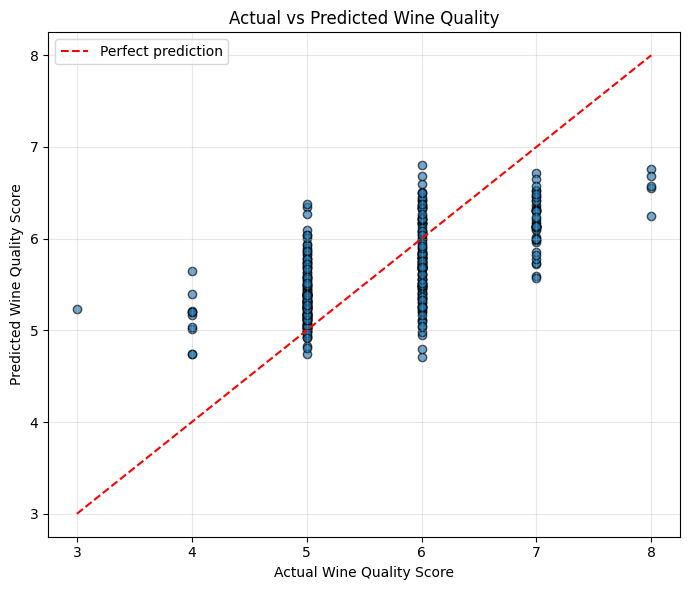

First 10 actual and predicted scores:


,Actual Quality,Predicted Quality
0,6,5.347
1,5,5.056
2,6,5.664
3,5,5.465
4,6,5.725
5,5,5.279
6,5,5.034
7,5,5.126
8,5,5.745
9,6,5.687


In [24]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.65,
    edgecolors="black"
)

# Reference line for perfect predictions
plot_min = min(y_test.min(), y_pred.min())
plot_max = max(y_test.max(), y_pred.max())

plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Wine Quality Score")
plt.ylabel("Predicted Wine Quality Score")
plt.title("Actual vs Predicted Wine Quality")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "04_actual_vs_predicted.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save actual and predicted scores
predictions_df = pd.DataFrame({
    "Actual Quality": y_test.to_numpy(),
    "Predicted Quality": y_pred
})

print("First 10 actual and predicted scores:")
display(predictions_df.head(10).round(3))

predictions_df.to_csv(
    os.path.join(OUTPUT_DIR, "task3_predictions.csv"),
    index=False
)

In [25]:
print("=" * 65)
print("TASK 4: BUSINESS DECISION-MAKING")
print("=" * 65)

print("\n(a) Recommended laboratory measurements")

print(
    f"1. Alcohol: correlation with quality = "
    f"{df['alcohol'].corr(df['quality']):.4f}"
)

print(
    f"2. Volatile acidity: correlation with quality = "
    f"{df['volatile acidity'].corr(df['quality']):.4f}"
)

print(
    "\nThese measurements deserve attention because they have "
    "the two strongest absolute Pearson correlations with quality "
    "in the red-wine dataset."
)

print("\n(b) Can regression replace sensory evaluation?")

print(f"Test MAE  = {mae:.4f}")
print(f"Test RMSE = {rmse:.4f}")
print(f"Test R-squared = {r2:.4f}")

print(
    f"The model explains approximately {r2 * 100:.2f}% "
    "of the variation in test-set quality scores."
)

print(
    "Recommendation: Use regression as a supporting screening "
    "tool, not as a complete replacement for sensory evaluation."
)

print("\n(c) Limitations")

print(
    "1. The quality scores are concentrated in certain categories, "
    "so the model may not predict uncommon quality scores reliably."
)

print(
    "2. The dataset contains duplicate rows, and a random train/test "
    "split may place identical records in both sets."
)

print(
    "3. Quality scores may depend on sensory factors that are not "
    "fully captured by the 11 laboratory measurements."
)

print("\nExact duplicate rows:", df.duplicated().sum())
print("Quality score distribution:")
print(df["quality"].value_counts().sort_index())

TASK 4: BUSINESS DECISION-MAKING

(a) Recommended laboratory measurements
1. Alcohol: correlation with quality = 0.4762
2. Volatile acidity: correlation with quality = -0.3906

These measurements deserve attention because they have the two strongest absolute Pearson correlations with quality in the red-wine dataset.

(b) Can regression replace sensory evaluation?
Test MAE  = 0.5035
Test RMSE = 0.6245
Test R-squared = 0.4032
The model explains approximately 40.32% of the variation in test-set quality scores.
Recommendation: Use regression as a supporting screening tool, not as a complete replacement for sensory evaluation.

(c) Limitations
1. The quality scores are concentrated in certain categories, so the model may not predict uncommon quality scores reliably.
2. The dataset contains duplicate rows, and a random train/test split may place identical records in both sets.
3. Quality scores may depend on sensory factors that are not fully captured by the 11 laboratory measurements.

Exac

In [26]:
import shutil

# Package all saved graphs and tables
results_zip = shutil.make_archive(
    "/content/wine_quality_results",
    "zip",
    OUTPUT_DIR
)

print("Results package created:")
print(results_zip)

# Download the ZIP to your computer
files.download(results_zip)

Results package created:
/content/wine_quality_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>